# Внимание — это всё, что нужно?
### Создание языковой модели трансформера с нуля

Этот ноутбук объясняет устройство небольшого декодера трансформера и воспроизводит эксперимент на русской художественной прозе. Модель обучалась со случайных весов; собственный BPE-словарь строился только на обучающей части корпуса.

Порядок работы: текст, токены, векторы, attention, причинная маска, обучение, проверка и генерация. В разделе о данных есть код, который скачивает исходные тексты, очищает их, удаляет повторы, разделяет произведения и строит словарь. Сам корпус в Git не хранится.

Для обычного запуска достаточно установить `requirements.txt` и выполнить `git lfs pull`. Веса находятся в `checkpoints/best.pt`. Длительная подготовка данных и обучение включаются отдельными флагами ниже. При выключенных флагах ноутбук показывает сохранённые измерения исходного опыта и выполняет генерацию.


In [1]:
from __future__ import annotations
from dataclasses import dataclass
from pathlib import Path
import html, json, math, sys
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from tokenizers import Tokenizer
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown

PROJECT = Path.cwd()
if not (PROJECT / "src" / "ruslit_lm" / "model.py").exists():
    PROJECT = next(p for p in [Path.cwd()/"attention_is_all_you_need", Path.cwd()/"outputs"/"attention_is_all_you_need"]
                   if (p/"src"/"ruslit_lm"/"model.py").exists())
DATA = PROJECT / "data"
ASSETS = PROJECT / "assets"
ASSETS.mkdir(exist_ok=True)
# Измеренный состав корпуса исходного эксперимента.
statistics = {'authors': 172,
 'documents': 3010,
 'tokens': 98259391,
 'splits': {'train': {'documents': 2723,
                      'text_utf8_bytes': 542078000,
                      'characters': 303861485,
                      'tokens': 89869929,
                      'tokens_without_eos': 89867206},
            'validation': {'documents': 139,
                           'text_utf8_bytes': 22355405,
                           'characters': 12513160,
                           'tokens': 3677706,
                           'tokens_without_eos': 3677567},
            'test': {'documents': 148,
                     'text_utf8_bytes': 28444806,
                     'characters': 15932251,
                     'tokens': 4711756,
                     'tokens_without_eos': 4711608}}}
tokenizer = Tokenizer.from_file(str(PROJECT/"tokenizer.json"))
device = "mps" if torch.backends.mps.is_available() else "cpu"
torch.set_num_threads(4)
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11, "axes.spines.top":False,
                     "axes.spines.right":False, "figure.facecolor":"white", "axes.facecolor":"white"})

def table(headers, rows):
    head = "".join(f"<th>{html.escape(str(x))}</th>" for x in headers)
    body = "".join("<tr>"+"".join(f"<td>{html.escape(str(x))}</td>" for x in row)+"</tr>" for row in rows)
    return HTML(f'<table class="research-table"><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>')

def integer(value):
    return f"{value:,}".replace(",","\u202f")

display(HTML("""<style>.research-table{border-collapse:collapse;max-width:100%;font:15px/1.5 sans-serif}
.research-table th,.research-table td{padding:8px 16px;border-bottom:1px solid #ddd;text-align:left}
.research-table th{border-bottom:2px solid #333}.jp-RenderedHTMLCommon h1{line-height:1.2}
.jp-RenderedHTMLCommon p{line-height:1.65}</style>"""))
print(f"Устройство: {device}; PyTorch {torch.__version__}; словарь: {tokenizer.get_vocab_size():,} токенов")

Matplotlib is building the font cache; this may take a moment.


Устройство: mps; PyTorch 2.14.1; словарь: 8,192 токенов


## 1. Задача языковой модели

Пусть есть начало фразы: «В старом доме было…». Мы хотим получить распределение вероятностей следующего **токена**. После выбора одного продолжения добавляем его к контексту и повторяем вычисление.

$$p(x_1,\ldots,x_T)=\prod_{t=1}^{T}p(x_t\mid x_1,\ldots,x_{t-1}).$$

Такое разложение задаёт авторегрессионную языковую модель. Она продолжает текст. Навык общения по инструкциям потребовал бы отдельного обучения и других данных.

## 2. Корпус и границы эксперимента

Мы собрали оригинальную русскую художественную прозу: романы, повести, рассказы и прозаические сказки. Отдельные стихотворные произведения, пьесы, письма, дневники и публицистику исключили по разметке источников и дополнительной жанровой проверке. В романах могут сохраняться стихотворные цитаты и естественные иностранные вкрапления.

Источники: [корпус нарративной прозы Пушкинского Дома](https://doi.org/10.31860/openlit-2020.10-C004), [RusLit](https://github.com/d0rj/RusLit), [Русский стилеметрический датасет](https://github.com/nevmenandr/RSD) и каталоги 42 классиков в [Lib.ru/Классике](http://az.lib.ru/). Полный список текстов и их происхождение сохранён в `manifest.jsonl`. Часть записей представляет сборники или части больших произведений, поэтому считаем именно **тексты корпуса**.

До разделения данных удаляем одинаковые записи, выбираем версии одного произведения и проверяем включение коротких текстов в сборники. Части одного произведения и тексты с большими общими фрагментами получают одну группу. Группа целиком попадает в train, validation или test. Токенизатор обучается только на train.

Для масштаба: в [официальном отчёте Qwen3](https://qwenlm.github.io/blog/qwen3/) описано около 36 трлн токенов предобучения. Размер нашего корпуса с собственным BPE показан ниже. Токенизаторы различаются, поэтому эти числа иллюстрируют порядок величины, а не задают точный коэффициент разницы в объёме текста или качестве.

### Скачивание и подготовка корпуса

Флаг `PREPARE_CORPUS` запускает полный конвейер из `data_pipeline/prepare.py`: загрузку закреплённых версий источников и текстов Lib.ru, очистку HTML, жанровый отбор, удаление повторов, группировку произведений, разделение на три выборки и обучение ByteLevel BPE. Результат записывается в `data/`; исходные загрузки кешируются. Готовая папка не перезаписывается.

По умолчанию длительная подготовка выключена. Чтобы повторить её, измените флаг на `True`. Обучение в разделе 9 также само подготовит данные, если они отсутствуют.

In [2]:
PREPARE_CORPUS = False
if PREPARE_CORPUS:
    import subprocess
    if not (DATA/"statistics.json").exists():
        subprocess.run([sys.executable,str(PROJECT/"data_pipeline"/"prepare.py"),
                        "--output-dir",str(DATA)],check=True)
    subprocess.run([sys.executable,str(PROJECT/"verify_corpus.py"),
                    "--data-dir",str(DATA)],check=True)
    statistics = json.loads((DATA/"statistics.json").read_text())
else:
    print("Подготовка корпуса выключена. Ниже показаны измерения исходного опыта.")

Подготовка корпуса выключена. Ниже показаны измерения исходного опыта.


Часть,Текстов,МБ UTF-8,Токенов с EOS
train,2 723,542.08,89 869 929
validation,139,22.36,3 677 706
test,148,28.44,4 711 756


Всего: 172 авторов, 3 010 текстов, 98.26 млн токенов.


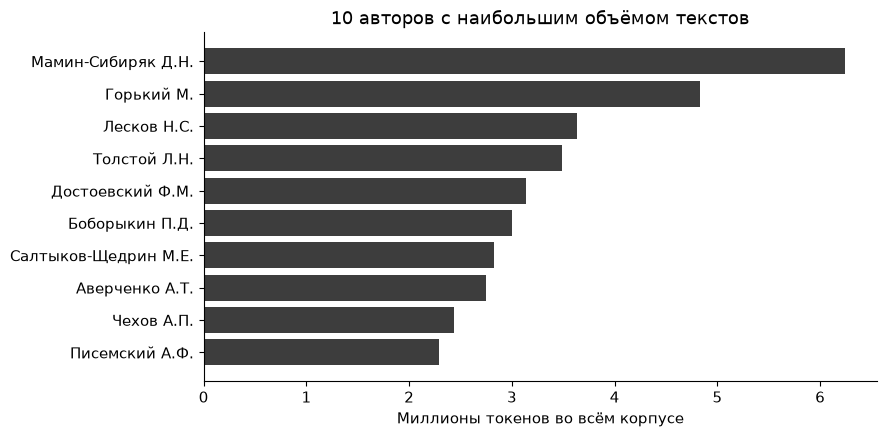

In [3]:
rows = []
for split, values in statistics["splits"].items():
    rows.append([split, integer(values["documents"]), f'{values["text_utf8_bytes"]/1e6:.2f}', integer(values["tokens"])])
display(table(["Часть", "Текстов", "МБ UTF-8", "Токенов с EOS"], rows))
print(f'Всего: {statistics["authors"]} авторов, {integer(statistics["documents"])} текстов, '
      f'{statistics["tokens"]/1e6:.2f} млн токенов.')
authors = [{'author': 'Мамин-Сибиряк Д.Н.', 'tokens': 6240789},
 {'author': 'Горький М.', 'tokens': 4832250},
 {'author': 'Лесков Н.С.', 'tokens': 3632697},
 {'author': 'Толстой Л.Н.', 'tokens': 3483106},
 {'author': 'Достоевский Ф.М.', 'tokens': 3139414},
 {'author': 'Боборыкин П.Д.', 'tokens': 2996469},
 {'author': 'Салтыков-Щедрин, Михаил Евграфович', 'tokens': 2824614},
 {'author': 'Аверченко А.Т.', 'tokens': 2750183},
 {'author': 'Чехов А.П.', 'tokens': 2434427},
 {'author': 'Писемский А.Ф.', 'tokens': 2285240}]
fig, ax = plt.subplots(figsize=(9,4.5))
top = authors[:10][::-1]
labels = [a["author"].replace(", Михаил Евграфович"," М.Е.") for a in top]
ax.barh(labels, [a["tokens"]/1e6 for a in top], color="#3d3d3d")
ax.set_xlabel("Миллионы токенов во всём корпусе")
ax.set_title("10 авторов с наибольшим объёмом текстов")
fig.tight_layout(); fig.savefig(ASSETS/"authors.png", dpi=170); plt.show()

## 3. Токены и эмбеддинги

Токен может совпадать со словом, частью слова, знаком пунктуации или фрагментом пробела. Наш BPE-словарь содержит 8192 элемента, включая специальные токены. Мы обучили его на собственных текстах; byte-level представление позволяет кодировать редкие символы.

У номера токена нет геометрического смысла. Эмбеддинг сопоставляет ему обучаемый вектор. В нашей модели это 512 чисел. К нему прибавляем вектор позиции, чтобы порядок слов влиял на результат:

$$X_t=E[x_t]+P[t].$$

Векторные представления слов появились раньше Word2Vec. Один из ранних примеров совместного обучения представлений и языковой модели — [Bengio и соавторы, 2003](https://jmlr.org/papers/v3/bengio03a.html).

In [4]:
example = "в старом доме было тихо."
encoded = tokenizer.encode(example)
display(table(["Позиция", "ID", "Фрагмент"],
              [[i, token, repr(tokenizer.decode([token]))] for i, token in enumerate(encoded.ids)]))
print("Обратное преобразование:", tokenizer.decode(encoded.ids))
assert tokenizer.decode(encoded.ids) == example

torch.manual_seed(7)
example_embedding = nn.Embedding(tokenizer.get_vocab_size(), 8)
vectors = example_embedding(torch.tensor(encoded.ids)).detach().numpy()
display(table(["ID", "Первые 4 координаты демонстрационного вектора"],
              [[token, np.round(vector[:4],3)] for token, vector in zip(encoded.ids,vectors)]))

Позиция,ID,Фрагмент
0,281,'в'
1,603,' стар'
2,303,'ом'
3,2162,' доме'
4,512,' было'
5,1731,' тихо'
6,15,'.'


Обратное преобразование: в старом доме было тихо.


ID,Первые 4 координаты демонстрационного вектора
281,[-0.53 -0.71 -1.044 0.827]
603,[-1.209 0.39 0.47 -0.255]
303,[ 0.336 0.249 -0.164 -1.703]
2162,[-0.113 -1.601 1.421 -1.181]
512,[ 1.803 0.344 0.25 -0.428]
1731,[0.748 1.129 1.154 0.175]
15,[-0.816 1.156 -1.211 0.507]


В последней таблице использованы случайные **демонстрационные** векторы размерности 8. Они показывают форму вычисления. Ниже создадим модель с размерностью 512 и загрузим её действительно обученные параметры.

## 4. Почему появился attention

RNN обрабатывает последовательность по шагам и обновляет скрытое состояние: $h_t=f(h_{t-1},E[x_t])$. Это полезная архитектура, но зависимость между шагами ограничивает параллельную обработку длинной последовательности.

Attention позволяет позиции напрямую использовать представления других доступных позиций. Механизм применяли в переводе до трансформера: [Bahdanau и соавторы, 2014](https://arxiv.org/abs/1409.0473). В [Transformer, 2017](https://arxiv.org/abs/1706.03762) авторы построили архитектуру без рекуррентных слоёв. Исходная модель содержала encoder и decoder для перевода. В нашем эксперименте используется только причинный decoder без cross-attention.

## 5. Q, K и V

Из входных представлений $X$ обучаемые линейные преобразования получают три матрицы:

$$Q=XW_Q+b_Q,\qquad K=XW_K+b_K,\qquad V=XW_V+b_V.$$

Названия удобно запомнить как «запрос», «ключ» и «значение». Это роли в вычислении, а не буквальные вопросы на естественном языке. Совместимость Q и K задаёт веса, с которыми смешиваются V:

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}+M\right)V.$$

Веса нормируются по строкам. Несколько голов attention выполняют разные обучаемые проекции параллельно; затем мы объединяем их результаты. В нашей модели 8 голов по 64 координаты.

### Маленький численный пример

Посчитаем одну голову для трёх позиций и двух координат. Числа Q, K и V ниже заданы вручную **только для демонстрации вычисления**. Это не веса или представления литературной модели. В каждой строке softmax получает доступ только к настоящему и прошлому. Итоговый вектор — взвешенная сумма строк V.

In [5]:
Q = torch.tensor([[1.,0.], [0.,1.], [1.,1.]])
K = torch.tensor([[1.,0.], [0.,1.], [1.,-1.]])
V = torch.tensor([[2.,0.], [0.,2.], [1.,1.]])
scores = Q @ K.T / math.sqrt(Q.shape[-1])
toy_mask = torch.ones(3,3,dtype=torch.bool).tril()
weights = scores.masked_fill(~toy_mask,float("-inf")).softmax(dim=-1)
mixed = weights @ V
assert torch.allclose(weights.sum(dim=-1),torch.ones(3))
display(table(["Позиция", "Вес позиции 1", "Вес позиции 2", "Вес позиции 3", "Результат: две координаты"],
    [[i+1,*[f"{p:.3f}" for p in weights[i]],str(np.round(mixed[i].numpy(),3))] for i in range(3)]))
print("Формы: Q",tuple(Q.shape),"; K",tuple(K.shape),"; V",tuple(V.shape),
      "; матрица весов",tuple(weights.shape),"; результат",tuple(mixed.shape))

Позиция,Вес позиции 1,Вес позиции 2,Вес позиции 3,Результат: две координаты
1,1.000,0.000,0.000,[2. 0.]
2,0.330,0.670,0.000,[0.66 1.34]
3,0.401,0.401,0.198,[1. 1.]


Формы: Q (3, 2) ; K (3, 2) ; V (3, 2) ; матрица весов (3, 3) ; результат (3, 2)


## 6. Причинная маска

Во время обучения подаём сразу все токены окна, но на позиции $t$ разрешаем доступ только к позициям $\leq t$. Будущие позиции получают $-\infty$ перед softmax и нулевой вес после него. Поэтому можно вычислять ошибки для всех позиций параллельно и сохранять задачу предсказания будущего.

Encoder обычно использует двусторонний контекст. Восстановление пропусков, как в [BERT](https://arxiv.org/abs/1810.04805), — один из способов его обучения. В нашей задаче decoder использует причинную маску и предсказывает следующий токен.

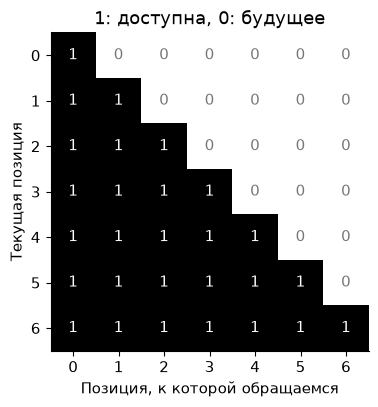

In [6]:
allowed = torch.ones(7,7,dtype=torch.bool).tril().numpy()
fig, ax = plt.subplots(figsize=(5,4.2))
ax.imshow(allowed, cmap="Greys", vmin=0, vmax=1)
for i in range(7):
    for j in range(7):
        ax.text(j,i,"1" if allowed[i,j] else "0",ha="center",va="center",
                color="white" if allowed[i,j] else "#777")
ax.set(xticks=range(7), yticks=range(7), xlabel="Позиция, к которой обращаемся", ylabel="Текущая позиция",
       title="1: доступна, 0: будущее")
fig.tight_layout(); fig.savefig(ASSETS/"causal-mask.png", dpi=170); plt.show()

## 7. Реализация модели

Сначала задаём конфигурацию. Attention реализован двумя способами: явное умножение матриц и `scaled_dot_product_attention`. Они задают одно вычисление; совпадение выходов и градиентов проверено отдельно. В длительном запуске используется SDPA.

In [7]:
@dataclass
class Config:
    vocab_size: int = 8192
    context_length: int = 512
    layers: int = 8
    width: int = 512
    heads: int = 8
    dropout: float = 0.1
    attention: str = 'sdpa'

    def __post_init__(self):
        if self.width % self.heads:
            raise ValueError('Model width must be divisible by the number of heads')
        if self.attention not in ('manual','sdpa'):
            raise ValueError('attention must be manual or sdpa')

In [8]:
class CausalSelfAttention(nn.Module):
    def __init__(self, config: Config):
        super().__init__()
        self.heads = config.heads
        self.head_width = config.width // config.heads
        self.method = config.attention
        self.dropout_probability = config.dropout
        self.qkv = nn.Linear(config.width, 3 * config.width)
        self.projection = nn.Linear(config.width, config.width)
        self.dropout = nn.Dropout(config.dropout)
        mask = torch.ones(config.context_length, config.context_length, dtype=torch.bool).tril()
        self.register_buffer('causal_mask', mask, persistent=False)

    def queries_keys_values(self, x):
        batch, length, _ = x.shape
        projections = self.qkv(x).chunk(3, dim=-1)
        return tuple(t.reshape(batch,length,self.heads,self.head_width).transpose(1,2)
                     for t in projections)

    def weights(self, x):
        q,k,_ = self.queries_keys_values(x)
        scores = q @ k.transpose(-2,-1) / math.sqrt(self.head_width)
        # Future positions receive -infinity before softmax, hence exactly zero weight.
        scores = scores.masked_fill(~self.causal_mask[:x.shape[1],:x.shape[1]], float('-inf'))
        return scores.softmax(dim=-1)

    def forward(self, x):
        batch, length, width = x.shape
        q,k,v = self.queries_keys_values(x)
        probability = self.dropout_probability if self.training else 0.0
        if self.method == 'manual':
            scores = q @ k.transpose(-2,-1) / math.sqrt(self.head_width)
            scores = scores.masked_fill(~self.causal_mask[:length,:length], float('-inf'))
            attention = F.dropout(scores.softmax(dim=-1),p=probability,training=self.training)
            result = attention @ v
        else:
            # The notebook derives the identical matrix calculation explicitly.
            result = F.scaled_dot_product_attention(q,k,v,is_causal=True,dropout_p=probability)
        result = result.transpose(1,2).contiguous().reshape(batch,length,width)
        return self.dropout(self.projection(result))

Блок содержит attention и MLP с GELU. Остаточные связи прибавляют обновление к исходному представлению, а LayerNorm нормирует признаки каждой позиции. Порядок нормализации — pre-norm:

$$x\leftarrow x+\operatorname{Attention}(\operatorname{LN}(x)),\qquad
x\leftarrow x+\operatorname{MLP}(\operatorname{LN}(x)).$$

In [9]:
class Block(nn.Module):
    def __init__(self, config: Config):
        super().__init__()
        self.norm_attention = nn.LayerNorm(config.width)
        self.attention = CausalSelfAttention(config)
        self.norm_mlp = nn.LayerNorm(config.width)
        self.mlp = nn.Sequential(nn.Linear(config.width,4*config.width),nn.GELU(),
                                 nn.Linear(4*config.width,config.width),nn.Dropout(config.dropout))

    def forward(self, x):
        x = x + self.attention(self.norm_attention(x))
        return x + self.mlp(self.norm_mlp(x))

Весь decoder объединяет эмбеддинги, позиции, восемь блоков и выходную проекцию. Матрица входных эмбеддингов используется также для получения выходных логитов: это связывание весов.

In [10]:
class Decoder(nn.Module):
    def __init__(self, config: Config):
        super().__init__()
        self.config = config
        self.tokens = nn.Embedding(config.vocab_size,config.width)
        self.positions = nn.Embedding(config.context_length,config.width)
        self.dropout = nn.Dropout(config.dropout)
        self.blocks = nn.ModuleList([Block(config) for _ in range(config.layers)])
        self.final_norm = nn.LayerNorm(config.width)
        self.apply(self._initialize)
        # Scale residual outputs to keep their initial variance stable across blocks.
        for block in self.blocks:
            nn.init.normal_(block.attention.projection.weight,std=.02/math.sqrt(2*config.layers))
            nn.init.normal_(block.mlp[2].weight,std=.02/math.sqrt(2*config.layers))

    @staticmethod
    def _initialize(module):
        if isinstance(module,(nn.Linear,nn.Embedding)):
            nn.init.normal_(module.weight,std=.02)
            if isinstance(module,nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

    @property
    def parameter_count(self):
        return sum(p.numel() for p in self.parameters())

    def forward(self, token_ids, targets=None, *, last_logits_only=False):
        if token_ids.shape[1] > self.config.context_length:
            raise ValueError('Input exceeds the configured context length')
        positions = torch.arange(token_ids.shape[1],device=token_ids.device)
        x = self.dropout(self.tokens(token_ids)+self.positions(positions))
        for block in self.blocks:
            x = block(x)
        x = self.final_norm(x)
        if last_logits_only:
            x = x[:,-1:,:]
        # Weight tying uses the same matrix for input embeddings and output logits.
        logits = F.linear(x,self.tokens.weight)
        loss = None if targets is None else F.cross_entropy(logits.flatten(0,1),targets.flatten())
        return logits,loss

    @torch.no_grad()
    def attention_maps(self, token_ids):
        self.eval()
        positions = torch.arange(token_ids.shape[1],device=token_ids.device)
        x = self.tokens(token_ids)+self.positions(positions)
        result=[]
        for block in self.blocks:
            result.append(block.attention.weights(block.norm_attention(x)).cpu())
            x = block(x)
        return result

    @torch.no_grad()
    def generate(self, token_ids, *, max_new_tokens=160,temperature=.8,top_k=50,
                 top_p=.95,eos_id=0,seed=42):
        self.eval()
        # Seed the CPU sampler; backend rounding can still change a continuation.
        generator = torch.Generator(device='cpu').manual_seed(seed)
        result = token_ids.clone()
        for _ in range(max_new_tokens):
            context = result[:,-self.config.context_length:]
            logits,_ = self(context,last_logits_only=True)
            scores = logits[0,-1].float().cpu()
            if temperature<=0:
                next_id = int(scores.argmax())
            else:
                scores = scores / temperature
                if top_k:
                    threshold = torch.topk(scores,min(top_k,scores.numel())).values[-1]
                    scores[scores<threshold] = float('-inf')
                if top_p<1:
                    ordered,indices = scores.sort(descending=True)
                    remove = ordered.softmax(dim=-1).cumsum(dim=-1)>top_p
                    remove[1:] = remove[:-1].clone();remove[0] = False
                    scores[indices[remove]] = float('-inf')
                next_id = int(torch.multinomial(scores.softmax(dim=-1),1,generator=generator))
            if next_id==eos_id:
                break
            token = torch.tensor([[next_id]],device=result.device,dtype=torch.long)
            result = torch.cat((result,token),dim=1)
        return result

In [11]:
config = Config()
model = Decoder(config)
display(table(["Параметр", "Значение"], [["Блоки",config.layers],["Ширина",config.width],
    ["Головы",config.heads],["Контекст",config.context_length],["Словарь",config.vocab_size],
    ["Обучаемые параметры",integer(model.parameter_count)]]))
assert model.parameter_count == 29_676_544

Параметр,Значение
Блоки,8
Ширина,512
Головы,8
Контекст,512
Словарь,8192
Обучаемые параметры,29 676 544


## 8. Проверка причинности и сдвиг целей

Вход содержит $x_0,\ldots,x_{T-1}$, а цели — $x_1,\ldots,x_T$. Меняя будущее во входе, не должны менять более ранние логиты. Следующая ячейка проверяет это на той же реализации без dropout.

In [12]:
torch.manual_seed(11)
small_config = Config(vocab_size=97,context_length=16,layers=2,width=32,heads=4,dropout=0)
small = Decoder(small_config).eval()
sequence = torch.randint(0,97,(2,17))
x, y = sequence[:,:-1], sequence[:,1:]
modified = x.clone(); modified[:,8:] = (modified[:,8:]+7)%97
with torch.no_grad():
    logits, loss = small(x,y)
    changed_logits,_ = small(modified)
prefix_error = float((logits[:,:8]-changed_logits[:,:8]).abs().max())
assert prefix_error < 1e-6
print("Вход:", tuple(x.shape), "; цели:", tuple(y.shape), "; логиты:", tuple(logits.shape))
print("Максимальное изменение логитов до изменённого будущего:", prefix_error)


Вход: (2, 16) ; цели: (2, 16) ; логиты: (2, 16, 97)
Максимальное изменение логитов до изменённого будущего: 0.0


## 9. Как модель обучалась

Cross-entropy усредняет отрицательный логарифм вероятности правильного следующего токена. Backpropagation вычисляет градиенты, AdamW обновляет параметры. Во время генерации будущих токенов ещё нет, и мы выбираем их последовательно.

Основной запуск: MPS, FP32, 16 окон по 512 токенов на шаг, dropout 0,1, AdamW, прогрев learning rate и cosine decay. Максимальная скорость обучения $6\cdot10^{-4}$. Веса матриц получают weight decay, bias и параметры нормализации — нет. Норма градиента ограничена единицей.

Лучший checkpoint выбирается по ошибке на фиксированной выборке validation. Test используется после обучения. Ограничение времени относится ко всему длительному запуску, включая промежуточные проверки и сохранения.

После основного этапа выполнено ещё 29 минут обучения той же модели на прежнем корпусе. Восстановлены оптимизатор, порядок данных и генераторы случайных чисел; learning rate зафиксирован на $3\cdot10^{-5}$. Продолжение ограничено тремя проходами по подготовленным окнам. Новые веса приняты по полной validation при заранее установленном минимальном выигрыше 0,005 нат на токен. Повторный test рассчитан после этого решения.

In [13]:
# Основное вычисление одного шага; пример использует маленькую проверочную модель.
small.train()
optimizer = torch.optim.AdamW(small.parameters(),lr=3e-4)
optimizer.zero_grad(set_to_none=True)
_, demonstration_loss = small(x,y)
demonstration_loss.backward()
torch.nn.utils.clip_grad_norm_(small.parameters(),1.0)
optimizer.step()
print("Один учебный шаг выполнен; loss =", round(float(demonstration_loss.detach()),4))

RUN_TRAINING = False
if RUN_TRAINING:
    import subprocess
    subprocess.run([
        sys.executable, str(PROJECT/"train.py"),
        "--data-dir", str(DATA), "--prepare-data",
        "--run-dir", str(PROJECT/"runs"/"experiment"), "--hours", "5.5"
    ], check=True)
else:
    print("Длительное обучение выключено. Ниже используются сохранённые веса.")


Один учебный шаг выполнен; loss = 4.5762
Длительное обучение выключено. Ниже используются сохранённые веса.


## 10. Результаты и сравнение

На графике показана средняя ошибка обучающих шагов и ошибка на отложенных произведениях. Perplexity равна экспоненте cross-entropy. Сравнивать её напрямую можно при одном токенизаторе и одном наборе оцениваемых позиций.

Для промежуточного графика берём фиксированные 262 144 позиции validation. Итоговая таблица оценивает все полные окна validation и test, поэтому её значения могут немного отличаться от промежуточной кривой.

Unigram-модель использует частоту токена, bigram-модель — частоту перехода от предыдущего токена. Сглаживание bigram выбиралось на validation. Для финального сравнения модели оцениваются на одинаковых полных окнах отложенных частей корпуса.

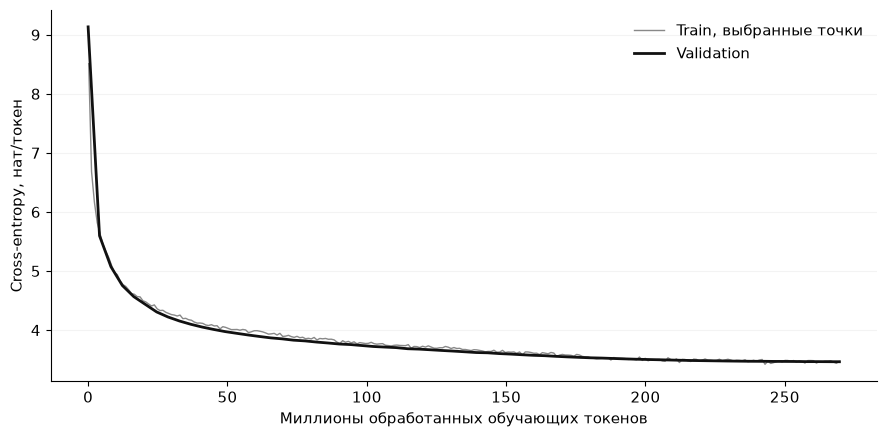

Модель,Validation NLL,Test NLL,Test perplexity
unigram,7.250,7.309,1493.7
bigram,5.080,5.099,163.9
transformer,3.461,3.429,30.9


Исходный опыт: 269,6 млн обработанных токенов, три прохода; 4 ч 56 мин активного обучения на принятом корпусе.


In [14]:
# Сохранённые измерения исходного опыта; они не выдаются за новый запуск.
train_curve = [[0.2048, 8.510100364685059],
 [1.2288, 6.683426380157471],
 [2.2528, 6.1654815673828125],
 [3.2768, 5.816685676574707],
 [4.3008, 5.628766059875488],
 [5.3248, 5.451433181762695],
 [6.3488, 5.335745334625244],
 [7.3728, 5.232243537902832],
 [8.3968, 5.097733020782471],
 [9.4208, 4.978116989135742],
 [10.4448, 4.940584182739258],
 [11.4688, 4.834394931793213],
 [12.4928, 4.770869255065918],
 [13.5168, 4.738893032073975],
 [14.5408, 4.682962417602539],
 [15.5648, 4.619105339050293],
 [16.5888, 4.606565952301025],
 [17.6128, 4.5668792724609375],
 [18.6368, 4.562545299530029],
 [19.6608, 4.497005462646484],
 [20.6848, 4.4775824546813965],
 [21.7088, 4.441678047180176],
 [22.7328, 4.408863544464111],
 [23.7568, 4.4266767501831055],
 [24.7808, 4.359858989715576],
 [25.8048, 4.331299304962158],
 [26.8288, 4.335241317749023],
 [27.8528, 4.302199363708496],
 [28.8768, 4.28260612487793],
 [29.9008, 4.262755393981934],
 [30.9248, 4.254766941070557],
 [31.9488, 4.238616466522217],
 [32.9728, 4.254255771636963],
 [33.9968, 4.193689346313477],
 [35.0208, 4.199310302734375],
 [36.0448, 4.176120758056641],
 [37.0688, 4.166955947875977],
 [38.0928, 4.136331558227539],
 [39.1168, 4.118678569793701],
 [40.1408, 4.120028495788574],
 [41.1648, 4.113253593444824],
 [42.1888, 4.087096691131592],
 [43.2128, 4.07771110534668],
 [44.2368, 4.091844081878662],
 [45.2608, 4.0702033042907715],
 [46.2848, 4.074146747589111],
 [47.3088, 4.020366668701172],
 [48.3328, 4.057977199554443],
 [49.3568, 4.045825958251953],
 [50.3808, 4.025941371917725],
 [51.4048, 4.008045196533203],
 [52.4288, 4.010005950927734],
 [53.4528, 4.01071834564209],
 [54.4768, 3.9978151321411133],
 [55.5008, 4.010946750640869],
 [56.5248, 4.002812385559082],
 [57.5488, 3.9579384326934814],
 [58.5728, 3.97111177444458],
 [59.5968, 3.9890780448913574],
 [60.6208, 3.9902613162994385],
 [61.6448, 3.980983257293701],
 [62.6688, 3.969722032546997],
 [63.6928, 3.9524004459381104],
 [64.7168, 3.9318952560424805],
 [65.7408, 3.936687707901001],
 [66.7648, 3.9450249671936035],
 [67.7888, 3.916957378387451],
 [68.8128, 3.945101737976074],
 [69.8368, 3.892634868621826],
 [70.8608, 3.8980214595794678],
 [71.8848, 3.911344051361084],
 [72.9088, 3.890021324157715],
 [73.9328, 3.877005100250244],
 [74.9568, 3.894322156906128],
 [75.9808, 3.8710989952087402],
 [77.0048, 3.878953218460083],
 [78.0288, 3.853921413421631],
 [79.0528, 3.8614728450775146],
 [80.0768, 3.8505852222442627],
 [81.1008, 3.8759915828704834],
 [82.1248, 3.8331916332244873],
 [83.1488, 3.8585174083709717],
 [84.1728, 3.8523948192596436],
 [85.1968, 3.858762741088867],
 [86.2208, 3.8446056842803955],
 [87.2448, 3.8461754322052],
 [88.2688, 3.8347764015197754],
 [89.2928, 3.797133684158325],
 [90.3168, 3.774151563644409],
 [91.3408, 3.820560932159424],
 [92.3648, 3.794431686401367],
 [93.3888, 3.809072256088257],
 [94.4128, 3.784195899963379],
 [95.4368, 3.801693916320801],
 [96.4608, 3.767162561416626],
 [97.4848, 3.788144826889038],
 [98.5088, 3.781010627746582],
 [99.5328, 3.7726519107818604],
 [100.5568, 3.775576114654541],
 [101.5808, 3.793321132659912],
 [102.6048, 3.770592451095581],
 [103.6288, 3.761768102645874],
 [104.6528, 3.7677483558654785],
 [105.6768, 3.770803213119507],
 [106.7008, 3.743703603744507],
 [107.7248, 3.7384819984436035],
 [108.7488, 3.732314348220825],
 [109.7728, 3.7422738075256348],
 [110.7968, 3.7466444969177246],
 [111.8208, 3.740586042404175],
 [112.8448, 3.7387425899505615],
 [113.8688, 3.7370352745056152],
 [114.8928, 3.753854274749756],
 [115.9168, 3.692899703979492],
 [116.9408, 3.723060369491577],
 [117.9648, 3.7203845977783203],
 [118.9888, 3.704425096511841],
 [120.0128, 3.726846218109131],
 [121.0368, 3.712712287902832],
 [122.0608, 3.733327627182007],
 [123.0848, 3.712860107421875],
 [124.1088, 3.6943793296813965],
 [125.1328, 3.6924242973327637],
 [126.1568, 3.7017180919647217],
 [127.1808, 3.7006542682647705],
 [128.2048, 3.7231268882751465],
 [129.2288, 3.710744619369507],
 [130.2528, 3.68867564201355],
 [131.2768, 3.704707145690918],
 [132.3008, 3.688868522644043],
 [133.3248, 3.691627264022827],
 [134.3488, 3.671701431274414],
 [135.3728, 3.6718530654907227],
 [136.3968, 3.663012742996216],
 [137.4208, 3.6537671089172363],
 [138.4448, 3.668414354324341],
 [139.4688, 3.665339946746826],
 [140.4928, 3.65620493888855],
 [141.5168, 3.646865129470825],
 [142.5408, 3.6323187351226807],
 [143.5648, 3.639143943786621],
 [144.5888, 3.6385083198547363],
 [145.6128, 3.659567356109619],
 [146.6368, 3.6274564266204834],
 [147.6608, 3.6280829906463623],
 [148.6848, 3.6571364402770996],
 [149.7088, 3.6207306385040283],
 [150.7328, 3.6300015449523926],
 [151.7568, 3.626399040222168],
 [152.7808, 3.630570650100708],
 [153.8048, 3.6085691452026367],
 [154.8288, 3.6296310424804688],
 [155.8528, 3.580533027648926],
 [156.8768, 3.630880355834961],
 [157.9008, 3.6295166015625],
 [158.9248, 3.6209421157836914],
 [159.9488, 3.6079490184783936],
 [160.9728, 3.6091387271881104],
 [161.9968, 3.585930824279785],
 [163.0208, 3.618779182434082],
 [164.0448, 3.6083295345306396],
 [165.0688, 3.5992867946624756],
 [166.0928, 3.621361017227173],
 [167.1168, 3.6112351417541504],
 [168.1408, 3.5531091690063477],
 [169.1648, 3.577587842941284],
 [170.1888, 3.5884079933166504],
 [171.2128, 3.578558921813965],
 [172.2368, 3.577488422393799],
 [173.2608, 3.5731942653656006],
 [174.2848, 3.5583465099334717],
 [175.3088, 3.5885753631591797],
 [176.3328, 3.577932834625244],
 [177.3568, 3.5543394088745117],
 [178.3808, 3.5470821857452393],
 [179.4048, 3.547046422958374],
 [180.4288, 3.529949903488159],
 [181.4528, 3.522578477859497],
 [182.4768, 3.5134003162384033],
 [183.5008, 3.517636775970459],
 [184.5248, 3.522902727127075],
 [185.5488, 3.5217320919036865],
 [186.5728, 3.5312180519104004],
 [187.5968, 3.4930357933044434],
 [188.6208, 3.536348581314087],
 [189.6448, 3.5232300758361816],
 [190.6688, 3.5224804878234863],
 [191.6928, 3.5211780071258545],
 [192.7168, 3.5183751583099365],
 [193.7408, 3.503784418106079],
 [194.7648, 3.506065607070923],
 [195.7888, 3.5049173831939697],
 [196.8128, 3.49699330329895],
 [197.8368, 3.5444977283477783],
 [198.8608, 3.4865777492523193],
 [199.8848, 3.522102117538452],
 [200.9088, 3.4807546138763428],
 [201.9328, 3.497499942779541],
 [202.9568, 3.492155075073242],
 [203.9808, 3.5000994205474854],
 [205.0048, 3.5034613609313965],
 [206.0288, 3.4780588150024414],
 [207.0528, 3.4720239639282227],
 [208.0768, 3.5314345359802246],
 [209.1008, 3.5014724731445312],
 [210.1248, 3.4889233112335205],
 [211.1488, 3.512284755706787],
 [212.1728, 3.4509506225585938],
 [213.1968, 3.5042433738708496],
 [214.2208, 3.5022432804107666],
 [215.2448, 3.477760076522827],
 [216.2688, 3.4687490463256836],
 [217.2928, 3.5091946125030518],
 [218.3168, 3.5043628215789795],
 [219.3408, 3.4723703861236572],
 [220.3648, 3.49227237701416],
 [221.3888, 3.5112128257751465],
 [222.4128, 3.4913330078125],
 [223.4368, 3.4888522624969482],
 [224.4608, 3.482285976409912],
 [225.4848, 3.4863498210906982],
 [226.5088, 3.507004737854004],
 [227.5328, 3.4833076000213623],
 [228.5568, 3.493886709213257],
 [229.5808, 3.5063822269439697],
 [230.6048, 3.49372935295105],
 [231.6288, 3.4761905670166016],
 [232.6528, 3.488598346710205],
 [233.6768, 3.4868171215057373],
 [234.7008, 3.479494094848633],
 [235.7248, 3.497572660446167],
 [236.7488, 3.4650235176086426],
 [237.7728, 3.474031925201416],
 [238.7968, 3.4896633625030518],
 [239.8208, 3.4727823734283447],
 [240.8448, 3.49314022064209],
 [241.8688, 3.5025320053100586],
 [242.8928, 3.421175003051758],
 [243.9168, 3.4731149673461914],
 [244.9408, 3.4355859756469727],
 [245.9648, 3.4489636421203613],
 [246.9888, 3.4644997119903564],
 [248.0128, 3.4798483848571777],
 [249.0368, 3.4608500003814697],
 [250.0608, 3.4870662689208984],
 [251.0848, 3.4858291149139404],
 [252.1088, 3.473234176635742],
 [253.1328, 3.484982967376709],
 [254.1568, 3.4576361179351807],
 [255.1808, 3.4786674976348877],
 [256.2048, 3.46866512298584],
 [257.2288, 3.4416887760162354],
 [258.2528, 3.4845476150512695],
 [259.2768, 3.484708547592163],
 [260.3008, 3.482738971710205],
 [261.3248, 3.4418468475341797],
 [262.3488, 3.4658308029174805],
 [263.3728, 3.4592740535736084],
 [264.3968, 3.473797559738159],
 [265.4208, 3.474438428878784],
 [266.4448, 3.482107639312744],
 [267.4688, 3.4584667682647705],
 [268.4928, 3.438128709793091],
 [269.5168, 3.4706575870513916]]
validation_curve = [[0.0, 9.133267402648926],
 [4.096, 5.596558094024658],
 [8.192, 5.072907447814941],
 [12.288, 4.754971504211426],
 [16.384, 4.566555023193359],
 [20.48, 4.436770915985107],
 [24.576, 4.307832717895508],
 [28.672, 4.221871852874756],
 [32.768, 4.154191017150879],
 [36.864, 4.098332405090332],
 [40.96, 4.051263332366943],
 [45.056, 4.011126518249512],
 [49.152, 3.9748425483703613],
 [53.248, 3.94598126411438],
 [57.344, 3.9179153442382812],
 [61.44, 3.89235258102417],
 [65.536, 3.868391752243042],
 [69.632, 3.8517699241638184],
 [73.728, 3.8293492794036865],
 [77.824, 3.8171961307525635],
 [81.92, 3.7977657318115234],
 [86.016, 3.7820067405700684],
 [90.112, 3.7644171714782715],
 [94.208, 3.7549290657043457],
 [98.304, 3.7385120391845703],
 [102.4, 3.7222766876220703],
 [106.496, 3.7127015590667725],
 [110.592, 3.7033798694610596],
 [114.688, 3.6844139099121094],
 [118.784, 3.6779637336730957],
 [122.88, 3.666701316833496],
 [126.976, 3.655132293701172],
 [131.072, 3.644561767578125],
 [135.168, 3.6329116821289062],
 [139.264, 3.6203291416168213],
 [143.36, 3.6156935691833496],
 [147.456, 3.6027135848999023],
 [151.552, 3.5939722061157227],
 [155.648, 3.583045482635498],
 [159.744, 3.5733017921447754],
 [163.84, 3.56680965423584],
 [167.936, 3.555692672729492],
 [172.032, 3.5465240478515625],
 [176.128, 3.538569927215576],
 [180.224, 3.531215190887451],
 [184.32, 3.5264577865600586],
 [188.416, 3.5197200775146484],
 [192.512, 3.5129780769348145],
 [196.608, 3.507136344909668],
 [200.704, 3.502479076385498],
 [204.8, 3.498138189315796],
 [208.896, 3.4935824871063232],
 [212.992, 3.4889607429504395],
 [217.088, 3.4849460124969482],
 [221.184, 3.482304334640503],
 [225.28, 3.479522705078125],
 [229.376, 3.4766178131103516],
 [233.472, 3.4743757247924805],
 [237.568, 3.472395896911621],
 [241.664, 3.471364974975586],
 [242.876416, 3.4716672897338867],
 [245.76, 3.470052719116211],
 [249.856, 3.4697766304016113],
 [253.952, 3.468583583831787],
 [258.048, 3.4663820266723633],
 [262.144, 3.4662961959838867],
 [266.24, 3.465050220489502],
 [269.59872, 3.464599132537842]]
evaluation_rows = [['unigram', 7.249505578457604, 7.309033079271517, 1493.7321700965085],
 ['bigram', 5.080248863117616, 5.099453533579702, 163.9322993214746],
 ['transformer', 3.4606054898641343, 3.4293395519982055, 30.856257065254173]]
fig, ax = plt.subplots(figsize=(9,4.5))
ax.plot(*np.asarray(train_curve).T,color="#888",linewidth=1,label="Train, выбранные точки")
ax.plot(*np.asarray(validation_curve).T,color="#111",linewidth=2,label="Validation")
ax.set(xlabel="Миллионы обработанных обучающих токенов",ylabel="Cross-entropy, нат/токен")
ax.legend(frameon=False);ax.grid(axis="y",alpha=.15)
fig.tight_layout();plt.show()
display(table(["Модель", "Validation NLL", "Test NLL", "Test perplexity"],
              [[name,f"{v:.3f}",f"{t:.3f}",f"{perplexity:.1f}"] for name,v,t,perplexity in evaluation_rows]))
print("Исходный опыт: 269,6 млн обработанных токенов, три прохода; 4 ч 56 мин активного обучения на принятом корпусе.")


## 11. Генерация

Загружаем checkpoint с лучшей ошибкой validation. Temperature меняет концентрацию распределения: меньшая температура усиливает наиболее вероятные продолжения, большая добавляет разнообразие. Top-k и top-p ограничивают выбор. Эти настройки не добавляют модели знаний.

Ниже можно изменить начало фразы, температуру и seed. Модель продолжает художественный текст. Длинный связный сюжет, следование инструкциям и устойчивое воспроизведение одного автора требуют отдельной проверки.

In [15]:
checkpoint = torch.load(PROJECT/"checkpoints"/"best.pt",map_location="cpu",weights_only=True)
model = Decoder(Config(**checkpoint["config"]))
model.load_state_dict(checkpoint["model"])
model = model.to(device).eval()
PROMPT = "Она остановилась у окна. За стеклом медленно"
TEMPERATURE = .8
SEED = 42
prompt_ids = torch.tensor([tokenizer.encode(PROMPT).ids],device=device)
generated = model.generate(prompt_ids,max_new_tokens=180,temperature=TEMPERATURE,seed=SEED)
print(tokenizer.decode(generated[0].tolist()))

Она остановилась у окна. За стеклом медленно шли какие-то тени, и в нем, казалось, было еще что-то, чего-то недоступного. Потом она начала было разглядывать его, и в этот миг они увидели себя как дома, и его лицо стало еще бледнее, чем прежде.

«Я не могу удержаться, — думал он, — я не могу уйти, я не могу удержаться!»

Но вдруг она быстро, быстро вскочила, и тотчас же, не оборачиваясь, быстро отошла от него.

Она откинула голову, схватила за волосы, быстро оглянула его и стала перед ним, закрыв лицо руками.

— Не могу, — сказала она. — Я сама не знаю, что у вас есть.

— Я знаю, что вы должны делать, — сказала она, как бы желая сказать.

Он поднял голову и


### Вероятности одного следующего токена

В таблице показан выход обученной модели для выбранного начала до temperature, top-k и top-p. Один наиболее вероятный токен ещё не определяет целое продолжение: после каждого выбора контекст меняется.

In [16]:
with torch.no_grad():
    next_logits,_ = model(prompt_ids[:,-config.context_length:],last_logits_only=True)
    next_probabilities = next_logits[0,-1].softmax(dim=-1).cpu()
probabilities, candidate_ids = next_probabilities.topk(8)
display(table(["ID", "Фрагмент", "Вероятность"],
    [[int(i),repr(tokenizer.decode([int(i)])),f"{float(p):.2%}"] for p,i in zip(probabilities,candidate_ids)]))

ID,Фрагмент,Вероятность
283,' и',4.92%
4435,' двиг',3.79%
13,"','",3.29%
3883,' мельк',2.90%
1670,' проб',2.60%
2017,' шел',1.99%
386,' вы',1.98%
4371,' тек',1.67%


### Одно начало до и после обучения

Для сравнения использованы заранее выбранные начала, одинаковые temperature 0,8, top-k 50, top-p 0,95 и seed 42. Начальная генерация ограничена 96 новыми токенами, финальная — 180. Текст сохранён прямо из модели, без литературной правки.

In [17]:
before = {'prompt': 'Она остановилась у окна. За стеклом медленно', 'text': 'Она остановилась у окна. За стеклом медленнохватрак слыхал черн поправ гляделорош беспокой догергша делом давно Афикат луч слова забавлыч увид откровенно назначранцузнаком анг глуп Антон поклон остановилисьче< смех смех смех адресальнойодиоди Лучрезерез остановились никаких никаких волос каждому молчалН Разусть жид настро\n план планферфер голенноразыг толпу концемо� любите концаозвол свид рассуд дороге азцер плечо0 большое Констант другимана рукуou концеленно лице лице пухЖеля упал буль выиг побежалстоятельстоятель извест берегу', 'seed': 42, 'temperature': 0.8}
after = {'prompt': 'Она остановилась у окна. За стеклом медленно', 'text': 'Она остановилась у окна. За стеклом медленно шли какие-то тени, и в нем, казалось, было еще что-то, чего-то недоступного. Потом она начала было разглядывать его, и в этот миг они увидели себя как дома, и его лицо стало еще бледнее, чем прежде.\n\n«Я не могу удержаться, — думал он, — я не могу уйти, я не могу удержаться!»\n\nНо вдруг она быстро, быстро вскочила, и тотчас же, не оборачиваясь, быстро отошла от него.\n\nОна откинула голову, схватила за волосы, быстро оглянула его и стала перед ним, закрыв лицо руками.\n\n— Не могу, — сказала она. — Я сама не знаю, что у вас есть.\n\n— Я знаю, что вы должны делать, — сказала она, как бы желая сказать.\n\nОн поднял голову и'}
display(Markdown("**Начало:** "+before["prompt"]))
print("Случайная инициализация:\n"+before["text"])
print("\nОбученный checkpoint:\n"+after["text"])


**Начало:** Она остановилась у окна. За стеклом медленно

Случайная инициализация:
Она остановилась у окна. За стеклом медленнохватрак слыхал черн поправ гляделорош беспокой догергша делом давно Афикат луч слова забавлыч увид откровенно назначранцузнаком анг глуп Антон поклон остановилисьче< смех смех смех адресальнойодиоди Лучрезерез остановились никаких никаких волос каждому молчалН Разусть жид настро
 план планферфер голенноразыг толпу концемо� любите концаозвол свид рассуд дороге азцер плечо0 большое Констант другимана рукуou концеленно лице лице пухЖеля упал буль выиг побежалстоятельстоятель извест берегу

Обученный checkpoint:
Она остановилась у окна. За стеклом медленно шли какие-то тени, и в нем, казалось, было еще что-то, чего-то недоступного. Потом она начала было разглядывать его, и в этот миг они увидели себя как дома, и его лицо стало еще бледнее, чем прежде.

«Я не могу удержаться, — думал он, — я не могу уйти, я не могу удержаться!»

Но вдруг она быстро, быстро вскочила, и тотчас же, не оборачиваясь, быстро отошла от него.

Она

## 12. Веса attention обученной модели

Карта ниже показывает одну голову первого слоя для короткого контекста. Веса будущих позиций равны нулю. Это визуализация одного вычисления attention; она сама по себе не объясняет все причины ответа модели.

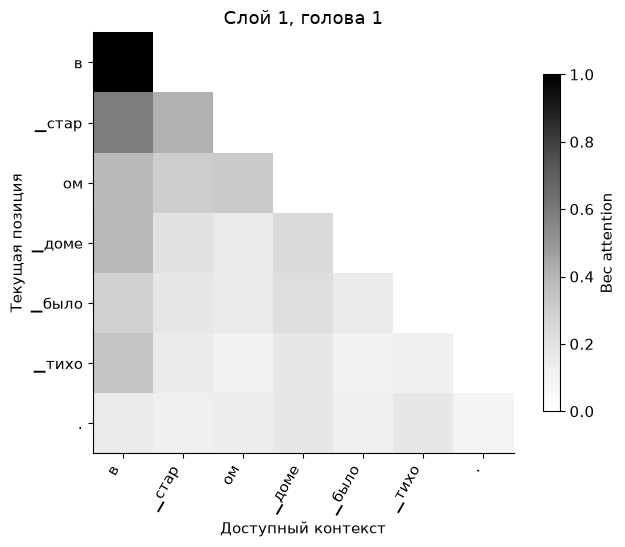

In [18]:
attention_text = "в старом доме было тихо."
attention_encoding = tokenizer.encode(attention_text)
attention_ids = torch.tensor([attention_encoding.ids],device=device)
weights = model.attention_maps(attention_ids)[0][0,0].numpy()
labels = [tokenizer.decode([i]).replace(" ","▁") for i in attention_encoding.ids]
fig, ax = plt.subplots(figsize=(7,5.6))
image = ax.imshow(weights,cmap="Greys",vmin=0)
ax.set_xticks(range(len(labels)),labels,rotation=60,ha="right")
ax.set_yticks(range(len(labels)),labels)
ax.set(xlabel="Доступный контекст",ylabel="Текущая позиция",title="Слой 1, голова 1")
fig.colorbar(image,ax=ax,label="Вес attention",shrink=.8)
fig.tight_layout();fig.savefig(ASSETS/"attention-map.png",dpi=180);plt.show()
assert np.count_nonzero(np.triu(weights,1)) == 0

## Выводы и ограничения

Эксперимент связывает понятную архитектуру с полным циклом: происхождение данных, собственный словарь, случайные веса, причинное предсказание, оптимизация, отложенные произведения и генерация.

Падение ошибки на новых текстах показывает улучшение предсказания в этом корпусе. Оно не доказывает наличие человеческого понимания или восстановление личности писателя. В генерации возможны повторы, ошибки согласования и потеря сюжета; модель ограничена контекстом 512 токенов и выбранной литературой.

Модель подходит для изучения устройства нейросетей и сравнения способов генерации. Для научного продолжения работы полезны контролируемые сравнения размера модели, контекста и состава данных при одинаковом вычислительном бюджете.

### Источники

- Bengio et al. [A Neural Probabilistic Language Model, 2003](https://jmlr.org/papers/v3/bengio03a.html).
- Mikolov et al. [Recurrent neural network based language model, 2010](https://www.isca-archive.org/interspeech_2010/mikolov10_interspeech.html).
- Bahdanau et al. [Neural Machine Translation by Jointly Learning to Align and Translate, 2014](https://arxiv.org/abs/1409.0473).
- Vaswani et al. [Attention Is All You Need, 2017](https://arxiv.org/abs/1706.03762).
- Devlin et al. [BERT, 2018](https://arxiv.org/abs/1810.04805).
- Karpathy. [nanoGPT](https://github.com/karpathy/nanoGPT): справочная реализация семейства GPT; готовые веса в этом проекте не используются.
- Собчук, Лекаревич. [Корпус нарративной прозы XIX в., V4](https://doi.org/10.31860/openlit-2020.10-C004).
- Орехов Б. [Русский стилеметрический датасет, 2026](https://doi.org/10.5281/zenodo.20701309).
- Источники отдельных текстов перечислены в манифесте корпуса.